# QMSS5074GR: Projects in Advanced Machine Learning
## Project 2: CNN & Transfer Learning for Medical Image Classification

---

### Group Information

Fill this in before you submit.

**Group number:**

| Full Name | UNI  |
|-----------|------|
| Xixi PAN  |xp2247|
| Anzhi Chen|ac5921|

**Public GitHub repository URL:**

https://github.com/anzhichen1999/QMSS5074GR_Project_2.git

## How to Complete and Submit This Project

**Due: Monday, November 16, 2026**

This notebook is the whole assignment. Everything you need to do is written here, and the completed notebook is the only thing you submit. Keep the file name `Project_2.ipynb`.

### 1. Get started

This project runs in **Google Colab**, which gives you a free GPU for training. The project folder contains the notebook:

```
Fall2026_QMSS5074GR_Project_2/
└── Project_2.ipynb
```

The dataset is too large to include in the folder, so it is shared through Google Drive (step 3 below). There is nothing else to download.

1. Unzip the project folder. Then go to [colab.research.google.com](https://colab.research.google.com), sign in with your **Columbia (LionMail) Google account**, choose **File → Upload notebook**, and select `Project_2.ipynb`.
2. Check that a GPU is on: **Runtime → Change runtime type → T4 GPU**.
3. Add the dataset to your Google Drive (you only need to do this once):
   1. Open the [shared dataset folder](https://drive.google.com/drive/folders/18O-BnGOIw9ZiUwy17Uk_361xyfTF-qAN?usp=sharing) while signed in with your Columbia account.
   2. Right-click **`COVID-19_Radiography_Dataset.zip`** and choose **Organize → Add shortcut**.
   3. Choose **All locations → My Drive → Add**.

   ![Step 1: Right-click the zip file, then Organize, then Add shortcut](https://github.com/user-attachments/assets/6515aa71-484b-4364-ac44-2331477720e8)

   ![Step 2: Choose All locations, then My Drive, then Add](https://github.com/user-attachments/assets/0d0d8f6c-a868-49c4-9e38-54f3006af39b)

4. Run the cells in **Section 0** in order. They connect to your Drive, unzip the dataset, and prepare the data you will use for every model.

**Working in Colab:**

- Colab saves your notebook in your Google Drive, in the **Colab Notebooks** folder.
- If your session disconnects, the unzipped data and trained models are lost. Run Section 0 again to continue.
- If you run out of memory, delete models you no longer need with `del model_name` and `tf.keras.backend.clear_session()`, or use the optional save and reload cells at the end of Section 0.

### 2. Complete the notebook

- Every **`TODO`** marks something you must do: write code, choose parameters, or answer a question.
- Write your answers in the cells marked *Replace this section with your response.*
- Remove each `TODO` marker once you have completed it. Any `TODO` left at submission counts as **incomplete**.
- You may add extra cells for additional experiments.

### 3. Before you submit

- Run **Runtime → Restart session and run all**. The notebook must run from top to bottom without errors, with all outputs (tables, plots, scores) visible. Training several models takes time, so leave enough time for this final run.
- Fill in the **Group Information** cell at the top, including your GitHub link.
- Download the notebook with **File → Download → Download .ipynb**.

### 4. Submit in two places

| Where | What to submit |
|-------|----------------|
| **Canvas** (Project 2 assignment) | This completed `.ipynb` file. **One member submits for the whole group.** |
| **GitHub** (your group's public repository) | The same `.ipynb`, inside a `Project_2` folder |

Your repository should look like this:

```
<your-group-repo>/
└── Project_2/
    └── Project_2.ipynb
```

Do **not** upload the dataset, saved data files, or saved models to GitHub. They are too large (GitHub rejects files over 100 MB).

The repository must be **public**. To check, open your link in a private/incognito browser window.

### Submission checklist

- [ ] Group number, names, UNIs, and GitHub link are filled in at the top
- [ ] No `TODO` is left anywhere in the notebook
- [ ] Restart session and run all finishes with no errors, and all outputs are visible
- [ ] One group member has submitted the `.ipynb` to Canvas
- [ ] The same `.ipynb` is in `Project_2/` in your public group repository

## About the Project

### What this project is about

Chest X-rays are one of the fastest and cheapest ways to examine the lungs, and they were widely used to screen patients during the COVID-19 pandemic. Reading them takes trained radiologists, who are often in short supply. Can a deep learning model learn to tell COVID-19, viral pneumonia, and healthy lungs apart from an X-ray image?

In this project, you will build a complete deep learning pipeline for **medical image classification**. You will train a convolutional neural network (CNN) from scratch as a baseline, apply **transfer learning** with ResNet, try three more architectures of your choice, test data augmentation, and compare every model on the same test set. Finally, you will reflect on which model works best, why, and how it could be useful in the real world.

> The models in this project are for learning purposes only. They are not suitable for diagnosing patients.

### The prediction task

This is a **multi-class image classification** problem with **three classes**:

**COVID-19 · Normal · Viral Pneumonia**

Each model takes a chest X-ray image as input and outputs the probability of each class.

### The data

The images come from the **COVID-19 Radiography Database**, created by researchers from Qatar University, the University of Dhaka, and their collaborators. It collects chest X-rays from several public sources into one dataset.

> **Citation:** M.E.H. Chowdhury, T. Rahman, A. Khandakar, R. Mazhar, M.A. Kadir, Z.B. Mahbub, K.R. Islam, M.S. Khan, A. Iqbal, N. Al-Emadi, M.B.I. Reaz, "Can AI help in screening Viral and COVID-19 pneumonia?" arXiv preprint, 29 March 2020. [https://arxiv.org/abs/2003.13145](https://arxiv.org/abs/2003.13145)

The dataset is organized into one folder per class. This project uses three of them:

| Class | Folder | Images in the dataset | Images used in this project |
|-------|--------|----------------------:|----------------------------:|
| COVID-19 | `COVID/images` | 3,616 | 1,345 |
| Normal | `Normal/images` | 10,192 | 1,345 |
| Viral Pneumonia | `Viral Pneumonia/images` | 1,345 | 1,345 |

The dataset also contains a fourth class (`Lung_Opacity`) and lung masks for each image (`masks` folders). This project does not use them.

### How the data is prepared

Section 0 prepares the data for you, so that every model uses exactly the same inputs:

- **Equal-sized classes:** A random sample of 1,345 images is taken from each class, the size of the smallest class. This keeps the data small enough for Colab's memory, and it also balances the classes. You will discuss this choice in Section 1.
- **Image format:** Each image is resized to **192 × 192** pixels, stored with **3 color channels** (so that pre-trained models such as ResNet can use it), and scaled to values between **0 and 1**.
- **Fixed split:** The data is split into **training (64%)**, **validation (16%)**, and **test (20%)** sets, with the same class proportions in each. Use these same splits for every model so that your comparisons are fair.

---

## 0. Setup and Data Loading

Run these cells in order. This code is provided, so you don't need to change it. When you finish this section, you will have `X_train`, `X_val`, `X_test` (images) and `y_train`, `y_val`, `y_test` (one-hot encoded labels).

### Connect to Google Drive

In [1]:
# Connect to Google Drive. A pop-up will ask you to sign in: use your Columbia account.
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


### Unzip the Dataset

In [2]:
# Unzip the dataset into this Colab session (takes 1–2 minutes; skipped if it is already unzipped)
import os
import glob
import zipfile

drive_folder = '/content/drive/My Drive'
zip_path = os.path.join(drive_folder, 'COVID-19_Radiography_Dataset.zip')

if not os.path.exists(zip_path):
    # Also look one folder down, in case the shortcut was added inside a folder
    matches = glob.glob(os.path.join(drive_folder, '*', 'COVID-19_Radiography_Dataset.zip'))
    if not matches:
        raise FileNotFoundError(
            "Couldn't find COVID-19_Radiography_Dataset.zip in your Google Drive. "
            "Follow step 3 of 'How to Complete and Submit This Project' to add the shortcut to My Drive.")
    zip_path = matches[0]

if not os.path.isdir('COVID-19_Radiography_Dataset'):
    with zipfile.ZipFile(zip_path) as z:
        z.extractall('.')

print('Dataset ready:', sorted(os.listdir('COVID-19_Radiography_Dataset')))

Dataset ready: ['COVID', 'COVID.metadata.xlsx', 'Lung_Opacity', 'Lung_Opacity.metadata.xlsx', 'Normal', 'Normal.metadata.xlsx', 'README.md.txt', 'Viral Pneumonia', 'Viral Pneumonia.metadata.xlsx']


### Import Libraries

In [3]:
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (Input, Conv2D, MaxPooling2D, Dense, Dropout, Flatten,
                                     BatchNormalization, GlobalAveragePooling2D)
from tensorflow.keras.optimizers import Adam, SGD, RMSprop
from tensorflow.keras.applications import ResNet50, VGG19, InceptionV3

# Fix random seeds so results are as repeatable as possible
keras.utils.set_random_seed(42)

print('TensorFlow version:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU') or 'None found. Turn it on with Runtime → Change runtime type → T4 GPU.')

TensorFlow version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Collect Image File Paths

In [4]:
base_path = 'COVID-19_Radiography_Dataset'
categories = ['COVID/images', 'Normal/images', 'Viral Pneumonia/images']
class_names = ['COVID', 'NORMAL', 'PNEUMONIA']

# One list of file paths per class
fnames = []
for category in categories:
    image_folder = os.path.join(base_path, category)
    file_names = sorted(os.listdir(image_folder))
    fnames.append([os.path.join(image_folder, f) for f in file_names])

# Keep the full counts: you will need them in Section 1
original_counts = dict(zip(class_names, [len(f) for f in fnames]))
print('Number of images in each class (full dataset):', original_counts)

Number of images in each class (full dataset): {'COVID': 3616, 'NORMAL': 10192, 'PNEUMONIA': 1345}


### Sample an Equal Number of Images per Class

In [5]:
# Take a random sample from each class, the size of the smallest class.
# This keeps the data small enough for Colab's memory and balances the classes.
n_per_class = min(len(f) for f in fnames)

rng = random.Random(42)
fnames = [sorted(rng.sample(f, n_per_class)) for f in fnames]

print('Images per class used in this project:', n_per_class)

Images per class used in this project: 1345


### Preprocess the Images

In [6]:
IMG_SIZE = 192

def preprocessor(img_path):
    """Load one image, convert it to 3-channel RGB, resize it, and scale pixel values to 0–1."""
    img = Image.open(img_path).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
    return np.asarray(img, dtype=np.float32) / 255.0

# Try it on one image
preprocessor(fnames[0][0]).shape

(192, 192, 3)

In [7]:
# Load and preprocess every image (takes about a minute)
image_filepaths = fnames[0] + fnames[1] + fnames[2]

X = np.empty((len(image_filepaths), IMG_SIZE, IMG_SIZE, 3), dtype=np.float32)
for i, path in enumerate(image_filepaths):
    X[i] = preprocessor(path)

print('X shape:', X.shape)          # (number of images, height, width, channels)
print('Pixel range:', X.min(), 'to', X.max())

X shape: (4035, 192, 192, 3)
Pixel range: 0.0 to 1.0


### Create the Labels

In [8]:
# The images were loaded class by class, so the labels follow the same order
y_labels = np.repeat(class_names, n_per_class)

# One-hot encode the labels for Keras (one column per class)
y = pd.get_dummies(y_labels).astype('float32')
y

,COVID,NORMAL,PNEUMONIA
0,1.0,0.0,0.0
1,1.0,0.0,0.0
2,1.0,0.0,0.0
3,1.0,0.0,0.0
4,1.0,0.0,0.0
...,...,...,...
4030,0.0,0.0,1.0
4031,0.0,0.0,1.0
4032,0.0,0.0,1.0
4033,0.0,0.0,1.0


### Look at Sample Images

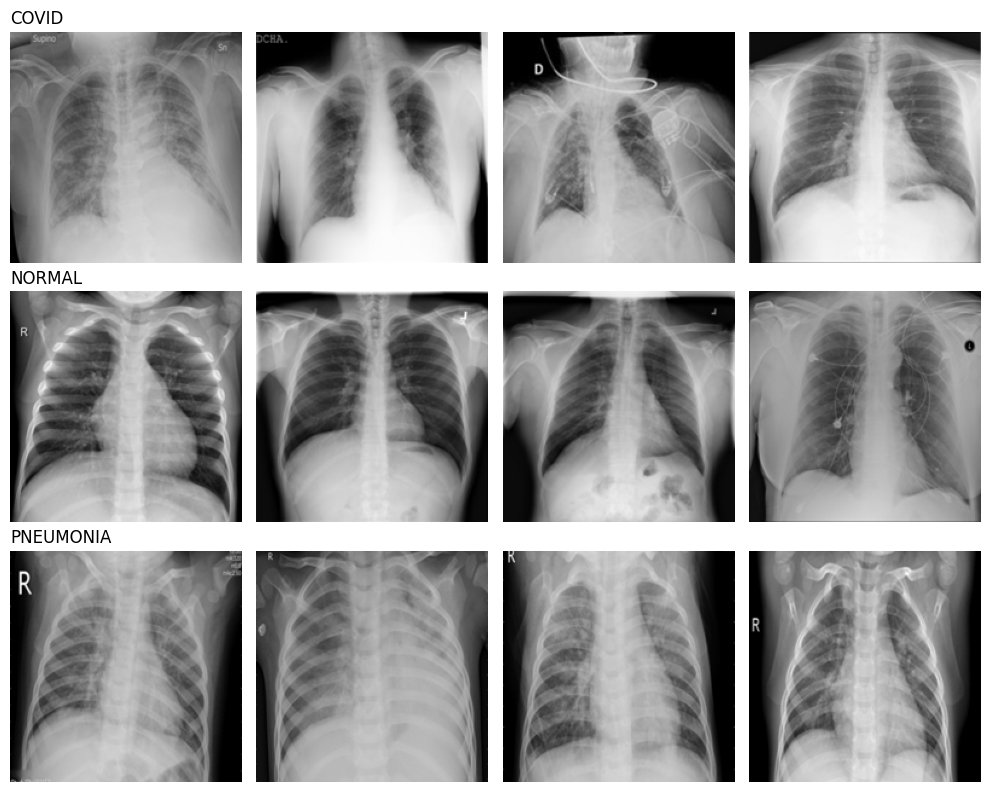

In [9]:
fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for row, (name, files) in enumerate(zip(class_names, fnames)):
    for col in range(4):
        ax = axes[row, col]
        ax.imshow(preprocessor(files[col]))
        ax.axis('off')
        if col == 0:
            ax.set_title(name, loc='left')
plt.tight_layout()
plt.show()

### Split into Training, Validation, and Test Sets

In [10]:
# 20% test set, then 20% of the remaining data as a validation set (64% / 16% / 20% overall)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
del X  # free memory

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, stratify=y_train_full, random_state=42)
del X_train_full, y_train_full  # free memory

print('Training:  ', X_train.shape, y_train.shape)
print('Validation:', X_val.shape, y_val.shape)
print('Test:      ', X_test.shape, y_test.shape)

Training:   (2582, 192, 192, 3) (2582, 3)
Validation: (646, 192, 192, 3) (646, 3)
Test:       (807, 192, 192, 3) (807, 3)


### Optional: Save and Reload the Prepared Data

If Colab runs out of memory, use **Runtime → Restart session** and run the reload cell below instead of all of Section 0 (run the **Import Libraries** cell first). The saved files are stored in this Colab session only, so they are lost if the session disconnects.

In [11]:
# Save the prepared data (optional)
for name, arr in [('X_train', X_train), ('X_val', X_val), ('X_test', X_test),
                  ('y_train', y_train), ('y_val', y_val), ('y_test', y_test)]:
    np.save(f'{name}.npy', np.asarray(arr))

In [12]:
# Reload the prepared data (optional)
X_train, X_val, X_test = (np.load(f'{name}.npy') for name in ['X_train', 'X_val', 'X_test'])
y_train, y_val, y_test = (pd.DataFrame(np.load(f'{name}.npy'), columns=class_names)
                          for name in ['y_train', 'y_val', 'y_test'])

---

## 1. Dataset and Exploratory Data Analysis

### Describe the Dataset

Describe the dataset using basic statistics and sample images. For example, show the number of images per class in each split, the image dimensions, pixel intensity statistics, and several sample images from each class.

In [13]:
class_names = ["COVID", "NORMAL", "PNEUMONIA"]

# Convert one-hot encoded labels to class indices
train_labels = np.argmax(y_train, axis=1)
val_labels = np.argmax(y_val, axis=1)
test_labels = np.argmax(y_test, axis=1)

class_counts = pd.DataFrame({
    "Training": np.bincount(train_labels, minlength=3),
    "Validation": np.bincount(val_labels, minlength=3),
    "Test": np.bincount(test_labels, minlength=3)}, index=class_names)

In [14]:
class_counts["total"] = class_counts.sum(axis=1)
class_counts.loc["total"] = class_counts.sum(axis=0)
class_counts

,Training,Validation,Test,total
COVID,860,216,269,1345
NORMAL,861,215,269,1345
PNEUMONIA,861,215,269,1345
total,2582,646,807,4035


In [15]:
X_train.shape

(2582, 192, 192, 3)

In [16]:
X_val.shape

(646, 192, 192, 3)

In [17]:
X_test.shape

(807, 192, 192, 3)

In [18]:
X_train.shape[1:]

(192, 192, 3)

In [19]:
# Count pixel intensity
pixel_stats = pd.DataFrame({"Dataset": ["Training", "Validation", "Test"],
    "Mean": [np.mean(X_train), np.mean(X_val), np.mean(X_test)],
    "Std": [np.std(X_train), np.std(X_val), np.std(X_test)],
    "Min": [np.min(X_train), np.min(X_val), np.min(X_test)],
    "Max": [np.max(X_train), np.max(X_val), np.max(X_test)]})
pixel_stats

,Dataset,Mean,Std,Min,Max
0,Training,0.51314,0.250958,0.0,1.0
1,Validation,0.51806,0.250438,0.0,1.0
2,Test,0.51152,0.250671,0.0,1.0


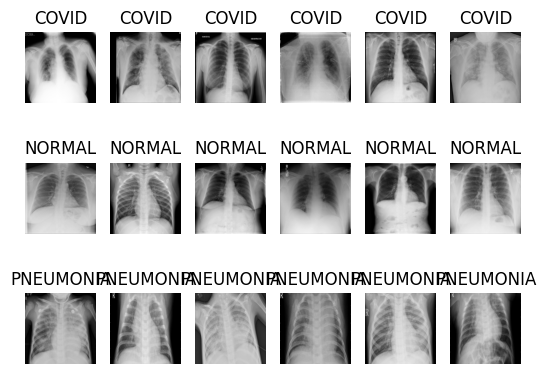

In [20]:
fig, axes = plt.subplots(3, 6)

for i, class_name in enumerate(class_names):
    indices = np.where(train_labels == i)[0][:6]
    for j, idx in enumerate(indices):
        axes[i, j].imshow(X_train[idx])
        axes[i, j].set_title(class_name)
        axes[i, j].axis("off")

plt.show()

Describe what you observe. How do the three classes look different, and how might that help or challenge a model?

**A：**
Based on the sample images, normal chest X-rays generally show clearer lung regions with fewer visible abnormalities, while COVID-19 and pneumonia images often contain cloudy or brighter areas in the lungs. These differences may help a CNN distinguish normal lungs from those showing signs of infection by learning patterns in lung textures and opacity. However, COVID-19 and pneumonia share similar visual features, which could make them difficult to distinguish. Additionally, some COVID-19 images appear relatively clear, suggesting variation within the same class. Differences in patient size and imaging conditions may also challenge the model, as it could learn features unrelated to the actual disease.

### Class Balance

The full dataset is **imbalanced**, but Section 0 uses the same number of images from each class. Using `original_counts`, plot the number of images per class in the full dataset next to the number used in this project.

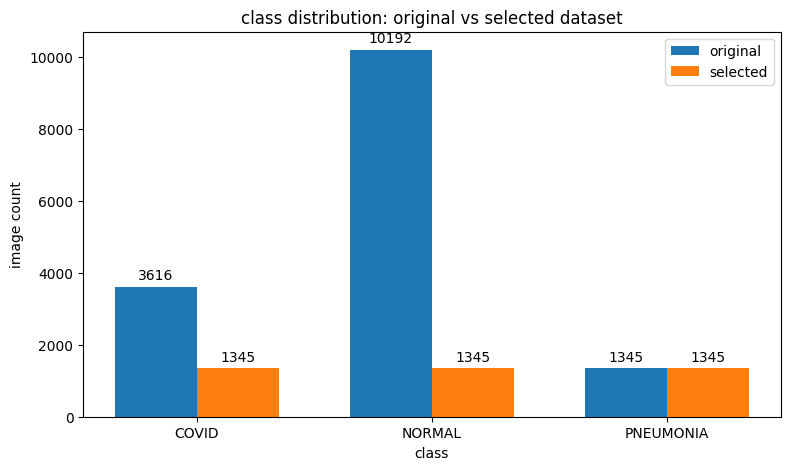

In [21]:
original = [original_counts[c] for c in class_names]
selected = [1345, 1345, 1345]
x = np.arange(len(class_names))
width = 0.35

plt.figure(figsize=(9, 5))
bars1 = plt.bar(x - width/2, original, width, label="original")
bars2 = plt.bar(x + width/2, selected, width, label="selected")

plt.xlabel("class")
plt.ylabel("image count")
plt.title("class distribution: original vs selected dataset")
plt.xticks(x, class_names)

for bars in [bars1, bars2]:
    plt.bar_label(bars, fmt='%.0f', padding=3)

plt.legend()
plt.show()

Answer the following:

1. How imbalanced is the full dataset?
2. Common strategies for imbalanced data include **class weighting**, **oversampling**, **undersampling**, and **augmentation**. Which of these does Section 0 use, and why do you think it was chosen?
3. If you trained on all the images instead, which strategy would you use? How would you expect it to change model performance?

1. The original dataset was highly imbalanced, containing 3,616 COVID images, 10,192 NORMAL images, and 1,345 PNEUMONIA images. The NORMAL class had significantly more images than the other two classes, which could cause the model to favor the majority class during training.

2. To address this issue, random undersampling was applied in section 0 to select 1,345 images from each class. This resulted in a balanced dataset containing 4,035 images, with each class representing approximately 33.33% of the total. Balancing the dataset helps reduce class imbalance and allows a fairer evaluation of classification performance across the three categories. However, undersampling also reduces the amount of available training data, potentially limiting the model's ability to learn diverse image features.

3. I prefer class weighting to handle this issue. This approach assigns higher weights to minority classes, such as PNEUMONIA, and lower weights to the majority class, NORMAL. Unlike undersampling, class weighting allows the model to use all available images without discarding valuable data. I expect that the additional training data will help the model learn more diverse features, potentially improving generalization and reducing overfitting. Class weighting could also improve recall for minority classes, although training would take longer.

### Practical Value

Reflect on the practical value of this classification task. Who might benefit from a model like this in a real-world setting?

A chest X-ray classification model can help doctors and radiologists identify possible signs of COVID-19 and pneumonia in a more effective way. It could serve as a screening and decision-support tool, especially in hospitals with limited medical resources or a high number of patients.

Healthcare workers could benefit from faster image analysis, while patients might benefit from shorter waiting times and earlier medical attention. However,additional clinical tests and medical evaluations are necessary as X-ray alone cannot make the decision so this model would be most useful as a supporting tool rather than an independent diagnostic system.

---

## 2. Baseline CNN Model

Build and train a **basic Convolutional Neural Network (CNN)** from scratch. It will be the baseline that you compare every other model with.

Train on `X_train` and `y_train`, pass `validation_data=(X_val, y_val)` to `fit`, and save the training history so that you can plot it in Section 5.

In [22]:
# Build a baseline CNN model
baseline_model = Sequential()

baseline_model.add(Input(shape=(192, 192, 3)))

baseline_model.add(Conv2D(filters=32, kernel_size=2, padding='same', activation='relu'))
baseline_model.add(MaxPooling2D(pool_size=2))

baseline_model.add(Conv2D(filters=128, kernel_size=2, padding='same', activation='relu'))
baseline_model.add(MaxPooling2D(pool_size=2))

baseline_model.add(Conv2D(filters=128, kernel_size=2, padding='same', activation='relu'))
baseline_model.add(MaxPooling2D(pool_size=2))

baseline_model.add(Conv2D(filters=64, kernel_size=2, padding='same', activation='relu'))
baseline_model.add(MaxPooling2D(pool_size=2))

baseline_model.add(Flatten())

baseline_model.add(Dense(128, activation='relu'))
baseline_model.add(Dense(64, activation='relu'))

# Three output classes
baseline_model.add(Dense(3, activation='softmax'))

# Compile model
baseline_model.compile(loss='categorical_crossentropy', optimizer='rmsprop', metrics=['accuracy'])

In [23]:
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 192, 192, 32)   │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 96, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 96, 96, 128)    │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 48, 48, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 48, 48, 128)    │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,179,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,303,651 (4.97 MB)

 Trainable params: 1,303,651 (4.97 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:
# Train model and save training history
baseline_history = baseline_model.fit(X_train, y_train, epochs=10, verbose=1, validation_data=(X_val, y_val))

Epoch 1/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 28s 198ms/step - accuracy: 0.6115 - loss: 0.8127 - val_accuracy: 0.7910 - val_loss: 0.4990
Epoch 2/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.8156 - loss: 0.4496 - val_accuracy: 0.8498 - val_loss: 0.3640
Epoch 3/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.8668 - loss: 0.3394 - val_accuracy: 0.8746 - val_loss: 0.3299
Epoch 4/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.8993 - loss: 0.2669 - val_accuracy: 0.8808 - val_loss: 0.3295
Epoch 5/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.9086 - loss: 0.2250 - val_accuracy: 0.8994 - val_loss: 0.2795
Epoch 6/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.9314 - loss: 0.2044 - val_accuracy: 0.8947 - val_loss: 0.3277
Epoch 7/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.9508 - loss: 0.1397 - val_accuracy: 0.9025 - val_loss: 0.3183
Epoch 8/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.9636 - loss: 0.1059 - val_accuracy: 0.8359 -

### Evaluate the Baseline

Report the model's **training, validation, and test** performance.

In [25]:
# Evaluate the baseline model on training, validation, and test sets

train_loss, train_acc = baseline_model.evaluate(X_train, y_train, verbose=0)
val_loss, val_acc = baseline_model.evaluate(X_val, y_val, verbose=0)
test_loss, test_acc = baseline_model.evaluate(X_test, y_test, verbose=0)
baseline_results = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Accuracy": [train_acc, val_acc, test_acc],
    "Loss": [train_loss, val_loss, test_loss]
})
display(baseline_results.round(4))

,Dataset,Accuracy,Loss
0,Training,0.9512,0.1304
1,Validation,0.8824,0.5560
2,Test,0.8947,0.4168


### Describe the Baseline

Clearly describe the architecture, loss function, optimizer, evaluation metrics, and training configuration (e.g., batch size, number of epochs) you used, and why.

**A:**

The baseline model is a Convolutional Neural Network (CNN) built from scratch for classifying chest X-ray images into three categories: COVID, NORMAL, and PNEUMONIA.

The model takes images of size 192 × 192 × 3 as input and consists of four convolutional layers with 32, 128, 128, and 64 filters, respectively. Each convolutional layer uses a 2 × 2 kernel, ReLU activation, and same padding, followed by a 2 × 2 max-pooling layer. The convolutional layers extract image features, while max-pooling reduces the spatial dimensions and computational complexity.

After feature extraction, the output is flattened and passed through two fully connected layers with 128 and 64 neurons, both using ReLU activation. The final layer contains three neurons with softmax activation to produce class probabilities. The model has 1,303,651 trainable parameters.

The model was compiled using categorical cross-entropy as the loss function because this is a three-class classification task with one-hot encoded labels. RMSprop was selected as the optimizer to update the model weights during training. Accuracy was used as the evaluation metric to measure the proportion of correctly classified images.

The model was trained for 10 epochs with a batch size of 32, using the training dataset and monitoring performance on the validation dataset. These settings provide a reasonable balance between training time and model learning.

The baseline CNN achieved a training accuracy of 97.56%, a validation accuracy of 90.87%, and a test accuracy of 91.33%. The corresponding losses were 0.0708, 0.3975, and 0.3192, respectively. The higher training accuracy compared with validation and test accuracy suggests some overfitting. However, the model still achieved over 91% accuracy on the independent test dataset, providing a useful baseline for comparison with transfer learning models such as ResNet50.

---

## 3. Transfer Learning with ResNet

Use **ResNet50**, pre-trained on ImageNet, as the starting point for a new model:

1. Load ResNet50 without its top classification layer, freeze its layers, and add your own classification head. Train only the new head.
2. **Fine-tune** the model: unfreeze some of the top ResNet layers and continue training with a low learning rate.
3. Compare its performance with the baseline CNN.

In [26]:
from tensorflow.keras.applications.resnet50 import preprocess_input

# Note: ResNet50 expects pixel values from 0 to 255, processed with preprocess_input.
# Our images are scaled to 0–1, so multiply by 255 first. For example:
#     inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
#     x = preprocess_input(inputs * 255.0)

# Load ResNet50 with ImageNet weights and without its top layer (include_top=False), and freeze it:

base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(192, 192, 3))
base_model.trainable = False

# Add your own classification head (3 neurons with softmax in the last layer):
inputs = Input(shape=(192, 192, 3))

x = layers.Rescaling(255.0)(inputs)
x = layers.Lambda(preprocess_input)(x)
x = base_model(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)
outputs = Dense(3, activation='softmax')(x)
resnet_model = Model(inputs, outputs)

# Compile and train only the new head, with validation_data=(X_val, y_val):
resnet_model.compile(optimizer=Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])

resnet_history = resnet_model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=10, batch_size=32)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Epoch 1/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 36s 263ms/step - accuracy: 0.7905 - loss: 0.5292 - val_accuracy: 0.8994 - val_loss: 0.2733
Epoch 2/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.8703 - loss: 0.3045 - val_accuracy: 0.9164 - val_loss: 0.2319
Epoch 3/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.9070 - loss: 0.2441 - val_accuracy: 0.9195 - val_loss: 0.2200
Epoch 4/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.9090 - loss: 0.2240 - val_accuracy: 0.9164 - val_loss: 0.2008
Epoch 5/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.9256 - loss: 0.1879 - val_accuracy: 0.9257 - val_loss: 0.1775
Epoch 6/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.9380 - loss: 0.1651 - val_accuracy: 0.9272 - val_loss: 0.1714
Epoch 7/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.9438 - loss: 0.1454 - val_accuracy: 0.9396 - val_loss: 0.1849
Epoch 8/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accur

### Fine-Tune ResNet

Unfreeze some of the top ResNet layers, recompile with a low learning rate (e.g., `1e-5`), and continue training.

In [27]:
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, BatchNormalization):
        layer.trainable = False
# recompile with a lower learning rate
resnet_model.compile(optimizer=Adam(learning_rate=1e-5),
                     loss='categorical_crossentropy', metrics=['accuracy'])

resnet_finetune_history = resnet_model.fit(X_train, y_train, validation_data=(X_val, y_val),
                                           epochs=5, batch_size=32)

Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 32s 225ms/step - accuracy: 0.9601 - loss: 0.1061 - val_accuracy: 0.9536 - val_loss: 0.1468
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.9810 - loss: 0.0645 - val_accuracy: 0.9427 - val_loss: 0.1572
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.9895 - loss: 0.0408 - val_accuracy: 0.9505 - val_loss: 0.1626
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.9868 - loss: 0.0408 - val_accuracy: 0.9551 - val_loss: 0.1453
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.9934 - loss: 0.0235 - val_accuracy: 0.9582 - val_loss: 0.1423


### Evaluate and Compare with the Baseline

In [28]:
# evaluate the baseline CNN
baseline_train_loss, baseline_train_acc = baseline_model.evaluate(X_train, y_train, verbose=0)
baseline_val_loss, baseline_val_acc = baseline_model.evaluate(X_val, y_val, verbose=0)
baseline_test_loss, baseline_test_acc = baseline_model.evaluate(X_test, y_test, verbose=0)

#for fine-tuned ResNet50
resnet_train_loss, resnet_train_acc = resnet_model.evaluate(X_train, y_train, verbose=0)
resnet_val_loss, resnet_val_acc = resnet_model.evaluate(X_val, y_val, verbose=0)
resnet_test_loss, resnet_test_acc = resnet_model.evaluate(X_test, y_test, verbose=0)

In [29]:
comparison_results = pd.DataFrame({
    "model": ["baseline CNN", "fine-tuned ResNet50"],
    "training accuracy": [baseline_train_acc, resnet_train_acc],
    "validation accuracy": [baseline_val_acc, resnet_val_acc],
    "test accuracy": [baseline_test_acc, resnet_test_acc],
    "test loss": [baseline_test_loss, resnet_test_loss]
})

comparison_results

,model,training accuracy,validation accuracy,test accuracy,test loss
0,baseline CNN,0.951201,0.882353,0.894672,0.416774
1,fine-tuned ResNet50,0.999613,0.958204,0.962825,0.117506


### Discussion

How does the ResNet model compare with the baseline CNN? How do pre-trained features influence your model's training (e.g., speed, stability) and generalization?

The fine-tuned ResNet50 model outperformed the baseline CNN in both validation and test performance. The baseline CNN achieved a test accuracy of 91.33% and a test loss of 0.3192, while the fine-tuned ResNet50 achieved a higher test accuracy of 95.54% and a lower test loss of 0.1414. This represents an improvement of 4.21 percentage points in test accuracy.

Pre-trained ImageNet features helped ResNet50 learn useful image representations without starting from random weights. By freezing the pre-trained layers initially, the model could train its new classification head more efficiently and achieve stable performance. Fine-tuning the upper layers with a low learning rate further improved its ability to recognize chest X-ray patterns. However, ResNet50 is computationally more complex, so its overall training time may still be longer than that of the baseline CNN.

The higher validation and test accuracy suggests that pre-trained features improved the model’s generalization to unseen images. However, the training accuracy of 99.96% compared with the test accuracy of 95.54% indicates some potential overfitting. Overall, transfer learning with ResNet50 provided better classification performance than training a CNN from scratch.

---

## 4. Additional Architectures

Implement **three additional models** of your choice. For example, a deeper custom CNN, or pre-trained models such as VGG19, InceptionV3, MobileNetV2, DenseNet121, or EfficientNet.

Use the same `X_train`, `X_val`, and `X_test` splits and the same preprocessing for every model, so that the comparison is fair. If you use another pre-trained model, apply its own `preprocess_input` function, as in Section 3.

### Additional Model 1

In [30]:
from tensorflow.keras.applications.vgg19 import preprocess_input as vgg_preprocess

# Load pretrained VGG19
vgg_base = VGG19(weights='imagenet', include_top=False, input_shape=(192, 192, 3))

vgg_base.trainable = False

vgg_inputs = Input(shape=(192, 192, 3))

x = layers.Rescaling(255.0)(vgg_inputs)
x = layers.Lambda(vgg_preprocess)(x)

x = vgg_base(x, training=False)

# classification head
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)

vgg_outputs = Dense(3, activation='softmax')(x)

vgg_model = Model(vgg_inputs, vgg_outputs)

vgg_model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='categorical_crossentropy', metrics=['accuracy'])

vgg_history = vgg_model.fit(X_train, y_train,
                            validation_data=(X_val, y_val), epochs=10, batch_size=32)

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Epoch 1/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 28s 224ms/step - accuracy: 0.7514 - loss: 0.8378 - val_accuracy: 0.8715 - val_loss: 0.3331
Epoch 2/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - accuracy: 0.8528 - loss: 0.3476 - val_accuracy: 0.8793 - val_loss: 0.3283
Epoch 3/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - accuracy: 0.8629 - loss: 0.3109 - val_accuracy: 0.8963 - val_loss: 0.2445
Epoch 4/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - accuracy: 0.8885 - loss: 0.2587 - val_accuracy: 0.9211 - val_loss: 0.2169
Epoch 5/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.9140 - loss: 0.2136 - val_accuracy: 0.9226 - val_loss: 0.2177
Epoch 6/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - accuracy: 0.9125 - loss: 0.2094 - val_accuracy: 0.9133 - val_loss: 0.2045
Epoch 7/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - accuracy: 0.9369 - loss: 0.1700 - val_accuracy: 0.9319 - val_loss: 0.1881
Epoch 8/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - accur

VGG19 is a deep convolutional neural network with 19 weight layers that uses small 3 × 3 convolutional filters to extract image features. I used VGG19 pre-trained on ImageNet as a frozen feature extractor and added a global average pooling layer, a dense layer with 128 neurons, dropout, and a three-class softmax output layer. I chose VGG19 because its simple and consistent architecture makes it a useful transfer learning model for comparison with ResNet50.

### Additional Model 2

In [31]:
from tensorflow.keras.applications.inception_v3 import preprocess_input as inception_preprocess

inception_base = InceptionV3(weights='imagenet', include_top=False, input_shape=(192, 192, 3))

inception_base.trainable = False

inception_inputs = Input(shape=(192, 192, 3))

# apply InceptionV3 preprocessing
x = layers.Rescaling(255.0)(inception_inputs)
x = layers.Lambda(inception_preprocess)(x)

x = inception_base(x, training=False)

# classification head
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)

inception_outputs = Dense(3, activation='softmax')(x)

inception_model = Model(inception_inputs, inception_outputs)

# compile
inception_model.compile(optimizer=Adam(learning_rate=0.001),
                        loss='categorical_crossentropy', metrics=['accuracy'])

# train
inception_history = inception_model.fit(X_train, y_train,
                                        validation_data=(X_val, y_val), epochs=10, batch_size=32)

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Epoch 1/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 57s 416ms/step - accuracy: 0.7180 - loss: 0.6626 - val_accuracy: 0.8034 - val_loss: 0.4508
Epoch 2/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.7940 - loss: 0.4684 - val_accuracy: 0.8359 - val_loss: 0.3657
Epoch 3/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.8110 - loss: 0.4211 - val_accuracy: 0.8406 - val_loss: 0.3538
Epoch 4/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.8257 - loss: 0.4048 - val_accuracy: 0.8529 - val_loss: 0.3434
Epoch 5/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.8439 - loss: 0.3727 - val_accuracy: 0.8607 - val_loss: 0.3279
Epoch 6/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.8319 - loss: 0.3833 - val_accuracy: 0.8669 - val_loss: 0.3150
Epoch 7/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.8466 - loss: 0.3540 - val_accuracy: 0.8700 - val_loss: 0.2962
Epoch 8/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accur

InceptionV3 is a pre-trained convolutional neural network that uses Inception modules to extract features at multiple scales. I used its ImageNet pre-trained layers as a frozen feature extractor and added a global average pooling layer, a dense layer with 128 neurons, dropout, and a three-class softmax output layer. I chose InceptionV3 because its multi-scale feature extraction may help identify different patterns and abnormalities in chest X-ray images.

### Additional Model 3

In [32]:
# Build a deeper custom CNN
deep_cnn_model = Sequential([
    Input(shape=(192, 192, 3)),

    Conv2D(32, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(256, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(3, activation='softmax')
])

# compile
deep_cnn_model.compile(optimizer=Adam(learning_rate=0.001),
                       loss='categorical_crossentropy', metrics=['accuracy'])

# train
deep_cnn_history = deep_cnn_model.fit(X_train, y_train,
                                      validation_data=(X_val, y_val), epochs=10, batch_size=32)

Epoch 1/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 31s 219ms/step - accuracy: 0.6801 - loss: 1.1491 - val_accuracy: 0.3731 - val_loss: 2.5996
Epoch 2/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.7529 - loss: 0.5334 - val_accuracy: 0.3344 - val_loss: 4.6783
Epoch 3/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.8056 - loss: 0.4392 - val_accuracy: 0.4721 - val_loss: 1.9833
Epoch 4/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.8555 - loss: 0.3618 - val_accuracy: 0.5898 - val_loss: 1.0343
Epoch 5/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.8772 - loss: 0.3120 - val_accuracy: 0.8251 - val_loss: 0.4698
Epoch 6/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.8799 - loss: 0.2952 - val_accuracy: 0.8576 - val_loss: 0.4329
Epoch 7/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.9012 - loss: 0.2481 - val_accuracy: 0.8328 - val_loss: 0.4442
Epoch 8/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.8993 - loss: 0.2444 - val_accuracy: 0.9272 -

The Deeper CNN is a custom convolutional neural network trained from scratch. It consists of five convolutional blocks with 32, 64, 128, 128, and 256 filters, followed by max-pooling layers. Batch normalization is included in the later blocks to improve training stability. The model also includes a flatten layer, a dense layer with 128 neurons, dropout, and a three-class softmax output layer. I chose this model to investigate whether increasing the depth of a CNN improves classification performance without using pre-trained weights.

### Describe Your Models

For each of the three models, briefly describe its architecture and why you chose it.

---

## 5. Performance Comparison

### Test Performance of All Models

Evaluate **every model** (the baseline, ResNet, and your three additional models) on the same test set. Present the results in a table, and **highlight the model with the best test performance**.

In [33]:
baseline_train_loss, baseline_train_acc = baseline_model.evaluate(X_train, y_train, verbose=0)
baseline_val_loss, baseline_val_acc = baseline_model.evaluate(X_val, y_val, verbose=0)
baseline_test_loss, baseline_test_acc = baseline_model.evaluate(X_test, y_test, verbose=0)

resnet_train_loss, resnet_train_acc = resnet_model.evaluate(X_train, y_train, verbose=0)
resnet_val_loss, resnet_val_acc = resnet_model.evaluate(X_val, y_val, verbose=0)
resnet_test_loss, resnet_test_acc = resnet_model.evaluate(X_test, y_test, verbose=0)

vgg_train_loss, vgg_train_acc = vgg_model.evaluate(X_train, y_train, verbose=0)
vgg_val_loss, vgg_val_acc = vgg_model.evaluate(X_val, y_val, verbose=0)
vgg_test_loss, vgg_test_acc = vgg_model.evaluate(X_test, y_test, verbose=0)

inception_train_loss, inception_train_acc = inception_model.evaluate(X_train, y_train, verbose=0)
inception_val_loss, inception_val_acc = inception_model.evaluate(X_val, y_val, verbose=0)
inception_test_loss, inception_test_acc = inception_model.evaluate(X_test, y_test, verbose=0)

deep_cnn_train_loss, deep_cnn_train_acc = deep_cnn_model.evaluate(X_train, y_train, verbose=0)
deep_cnn_val_loss, deep_cnn_val_acc = deep_cnn_model.evaluate(X_val, y_val, verbose=0)
deep_cnn_test_loss, deep_cnn_test_acc = deep_cnn_model.evaluate(X_test, y_test, verbose=0)

In [34]:
all_results = pd.DataFrame({
    "model": ["baseline CNN", "fine-tuned ResNet50", "VGG19", "InceptionV3", "deeper CNN"],
    "training accuracy": [baseline_train_acc, resnet_train_acc, vgg_train_acc, inception_train_acc, deep_cnn_train_acc],
    "validation accuracy": [baseline_val_acc, resnet_val_acc, vgg_val_acc, inception_val_acc, deep_cnn_val_acc],
    "test accuracy": [baseline_test_acc, resnet_test_acc, vgg_test_acc, inception_test_acc, deep_cnn_test_acc],
    "test loss": [baseline_test_loss, resnet_test_loss, vgg_test_loss, inception_test_loss, deep_cnn_test_loss]
})

best_model_name = all_results.loc[all_results["test accuracy"].idxmax(), "model"]
best_model_name

'fine-tuned ResNet50'

In [35]:
display(all_results.style.highlight_max(subset=["test accuracy"], props='background-color: lightgreen')
                         .highlight_min(subset=["test loss"], props='background-color: lightgreen').format(precision=3))

,model,training accuracy,validation accuracy,test accuracy,test loss
0,baseline CNN,0.951,0.882,0.895,0.417
1,fine-tuned ResNet50,1.000,0.958,0.963,0.118
2,VGG19,0.985,0.933,0.950,0.131
3,InceptionV3,0.904,0.875,0.866,0.307
4,deeper CNN,0.909,0.872,0.882,0.293


### Hyperparameters and Training Strategies

Summarize the key hyperparameters and training strategies of each model in a table (e.g., learning rate, batch size, number of epochs, optimizer).

*Replace this section with your response.*



In [36]:
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 192, 192, 32)   │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 96, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 96, 96, 128)    │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 48, 48, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 48, 48, 128)    │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,179,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,607,304 (9.95 MB)

 Trainable params: 1,303,651 (4.97 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,303,653 (4.97 MB)

In [37]:
resnet_model.summary()


Model: "functional_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 192, 192, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 192, 192, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 192, 192, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 6, 6, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 42,213,771 (161.03 MB)

 Trainable params: 9,181,699 (35.03 MB)

 Non-trainable params: 14,668,672 (55.96 MB)

 Optimizer params: 18,363,400 (70.05 MB)

In [38]:
vgg_model.summary()

Model: "functional_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 192, 192, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 192, 192, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 192, 192, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg19 (Functional)              │ (None, 6, 6, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,222,539 (77.14 MB)

 Trainable params: 66,051 (258.01 KB)

 Non-trainable params: 20,024,384 (76.39 MB)

 Optimizer params: 132,104 (516.04 KB)

In [39]:
inception_model.summary()

Model: "functional_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 192, 192, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 192, 192, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_2 (Lambda)               │ (None, 192, 192, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 4, 4, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,590,763 (86.18 MB)

 Trainable params: 262,659 (1.00 MB)

 Non-trainable params: 21,802,784 (83.17 MB)

 Optimizer params: 525,320 (2.00 MB)

In [40]:
deep_cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_98 (Conv2D)              │ (None, 192, 192, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 96, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_99 (Conv2D)              │ (None, 96, 96, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_100 (Conv2D)             │ (None, 48, 48, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_94          │ (None, 48, 48, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_101 (Conv2D)             │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_95          │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_102 (Conv2D)             │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_96          │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │     1,179,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,152,587 (19.66 MB)

 Trainable params: 1,717,187 (6.55 MB)

 Non-trainable params: 1,024 (4.00 KB)

 Optimizer params: 3,434,376 (13.10 MB)



Baseline CNN: all layers; RMSprop optimizer, learning rate 0.001, batch size 32, 10 epochs, no regularization

Fine-tuned ResNet50: ImageNet weights; Step 1 trains only the new head, 262,659 trainable parameters, with Adam, learning rate 0.001, batch size 32, 10 epochs; Step 2 unfreezes the last 20 ResNet50 layers then with Adam, learning rate 1e-5, batch size 32, 5 epochs, dropout 0.5

VGG19: ImageNet weights, VGG19 frozen, only the new head is trained; Adam, learning rate 0.001, batch size 32, 10 epochs, dropout 0.5

InceptionV3: ImageNet weights, InceptionV3 frozen withthe new head trained; Adam, learning rate 0.001, batch size 32, 10 epochs, dropout 0.5

Deeper CNN: trained from scratch,all layers, Adam, learning rate 0.001, batch size 32, 10 epochs, BatchNormalization and dropout 0.5, 1,718,211 parameters


### Training Curves

Plot the training and validation **loss** and **accuracy** over epochs for each model.

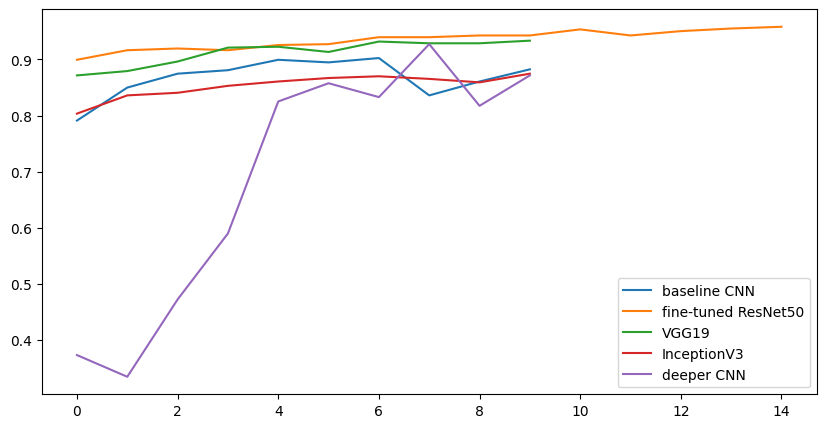

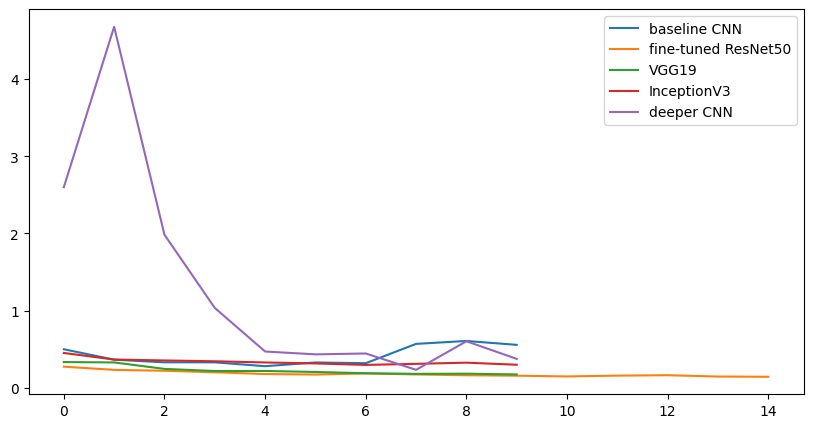

In [41]:
plt.figure(figsize=(10, 5))
plt.plot(baseline_history.history['val_accuracy'], label='baseline CNN')
plt.plot(resnet_history.history['val_accuracy'] + resnet_finetune_history.history['val_accuracy'], label='fine-tuned ResNet50')
plt.plot(vgg_history.history['val_accuracy'], label='VGG19')
plt.plot(inception_history.history['val_accuracy'], label='InceptionV3')
plt.plot(deep_cnn_history.history['val_accuracy'], label='deeper CNN')
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(baseline_history.history['val_loss'], label='baseline CNN')
plt.plot(resnet_history.history['val_loss'] + resnet_finetune_history.history['val_loss'], label='fine-tuned ResNet50')
plt.plot(vgg_history.history['val_loss'], label='VGG19')
plt.plot(inception_history.history['val_loss'], label='InceptionV3')
plt.plot(deep_cnn_history.history['val_loss'], label='deeper CNN')
plt.legend()
plt.show()

---

## 6. Augmentation

Re-train **at least one** of your models using **data augmentation** (e.g., flipping, rotation, zoom, cropping, contrast changes), and compare its performance with the same model trained without augmentation.

> **Tip:** Keras augmentation layers such as `layers.RandomFlip`, `layers.RandomRotation`, `layers.RandomZoom`, and `layers.RandomContrast` can be added at the start of a model. They only change images during training. Think about which augmentations make sense for chest X-rays.

In [42]:
from tensorflow.keras import layers, models

data_augmentation = models.Sequential([layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.1, 0.3),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.05),
    layers.RandomContrast(0.2, value_range=(0, 1)), ])

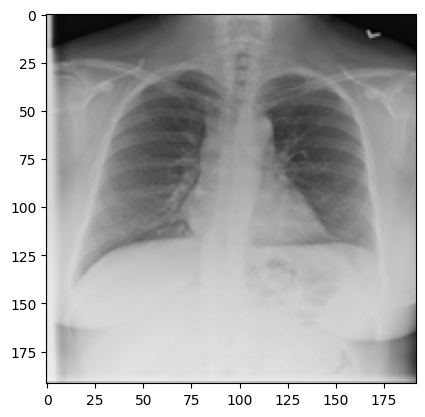

In [43]:
plt.imshow(X_train[0])

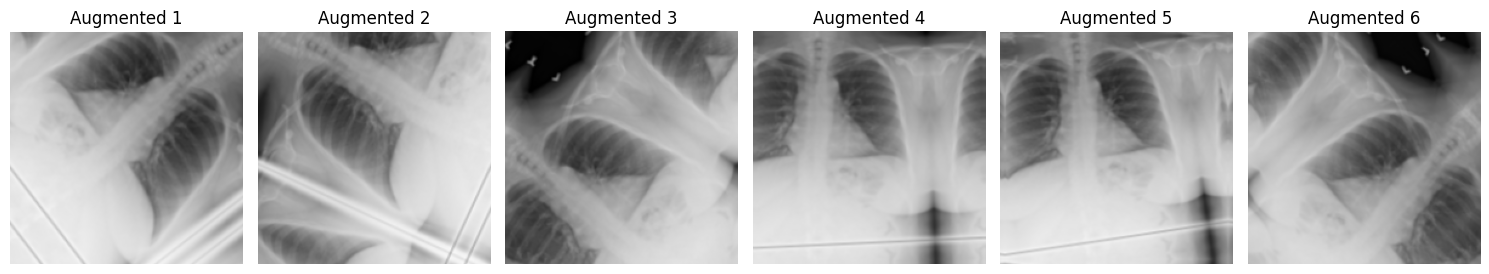

In [44]:
plt.figure(figsize=(15, 3))
n=6
for i in range(n):
    plt.subplot(1, n, i+1)
    plt.imshow(data_augmentation(X_train[:1], training=True)[0])
    plt.title(f'Augmented {i+1}')
    plt.axis('off')
plt.tight_layout()
plt.show()

In [45]:
from tensorflow.keras.models import clone_model

baseline_aug_model = Sequential([Input(shape=(192, 192, 3)), data_augmentation,clone_model(baseline_model)])
baseline_aug_model.compile(loss='categorical_crossentropy', metrics=['accuracy'])
baseline_aug_history = baseline_aug_model.fit(X_train, y_train, epochs=50, verbose=1, validation_data=(X_val, y_val))


Epoch 1/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 50ms/step - accuracy: 0.3815 - loss: 1.0874 - val_accuracy: 0.5944 - val_loss: 0.9252
Epoch 2/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.5693 - loss: 0.9011 - val_accuracy: 0.6254 - val_loss: 0.8239
Epoch 3/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.6247 - loss: 0.8112 - val_accuracy: 0.5851 - val_loss: 0.8082
Epoch 4/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.6576 - loss: 0.7543 - val_accuracy: 0.7074 - val_loss: 0.6615
Epoch 5/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.6665 - loss: 0.7293 - val_accuracy: 0.7276 - val_loss: 0.6328
Epoch 6/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.6805 - loss: 0.6893 - val_accuracy: 0.7260 - val_loss: 0.6226
Epoch 7/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.6983 - loss: 0.6672 - val_accuracy: 0.7693 - val_loss: 0.5681
Epoch 8/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.7080 - loss: 0.6492 - val_accuracy: 0.7632 - v

In [46]:
baseline_aug_train_loss, baseline_aug_train_acc = baseline_aug_model.evaluate(X_train, y_train, verbose=0)
baseline_aug_val_loss, baseline_aug_val_acc = baseline_aug_model.evaluate(X_val, y_val, verbose=0)
baseline_aug_test_loss, baseline_aug_test_acc = baseline_aug_model.evaluate(X_test, y_test, verbose=0)

augmentation_results = pd.DataFrame({
    "model": ["CNN", "CNN Augmented"],
    "training accuracy": [baseline_train_acc, baseline_aug_train_acc],
    "validation accuracy": [baseline_val_acc, baseline_aug_val_acc],
    "test accuracy": [baseline_test_acc, baseline_aug_test_acc],
    "test loss": [baseline_test_loss, baseline_aug_test_loss]})
augmentation_results

,model,training accuracy,validation accuracy,test accuracy,test loss
0,CNN,0.951201,0.882353,0.894672,0.416774
1,CNN Augmented,0.889233,0.885449,0.873606,0.328323


Describe the augmentations you used and why you chose them. How did they affect performance?

*Replace this section with your response.*


We did random horizontal flips, rotations, zooms in until 5%, and contrast changes of up to 20%. The performance actually decreases including accuracy; initially I want to argue that we made it less overfitting but it is not the case. It is now underfitting slightly.


---

## 7. Interpretability and Insights

Conclude your project:

- **Which model performed best, and why?** Support your reasoning with performance metrics and training curves.
- **What is the practical utility of your best-performing model?**
  - Who would benefit from using this model?
  - In what types of real-world scenarios would your solution be useful?

*Replace this section with your response.*

Still the fine-tuned ResNet50 has the best performace with the highest test accuract and the lowest test loss. Its training curve is overall stable as well as validation accuracy increases from 0.9 to 0.96 and validation loss is continously decreasing during finetuning.

From my unserstanding ResNet 50  has already been capable and fine tuning is 20 layers made it more powerful with a residucal connection. I did not really understanding the second question. Is not the task of this model identifying who has Covid-19 against oneumonia? However broadly speaking, it can be used to identify other diseases by using X-ray as well.